# 그래프 구조

In [9]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.documents import Document

class State(TypedDict):
    question: Annotated[str, add_messages]
    context: Annotated[str, "The context for the question"]
    vector_docs: Annotated[list[Document], "The vectorized documents for retrieval"]
    Web_docs: Annotated[list[Document], "The web documents for retrieval"]
    result: Annotated[str, "The final answer to the user's question"]
    message: Annotated[str, add_messages]
    relevance: Annotated[str, "The relevance score of the retrieved documents"]


## 노드(Node) 정의

In [13]:
def retrieve_vector_documents(state: State) -> State:
    """logic 구현
    response_from_vector_retrieval = []  #이런 식으로 실제 구현
    return State(
        "vector_docs": response_from_vector_retrieval
    )"""

def retrieve_web_documents(state: State) -> State:
    """logic 구현
    #response_from_web_retrieval = []  #이런 식으로 실제 구현
    return State(
        "Web_docs": response_from_web_retrieval
    )"""

def unify_documents(state: State) -> State:
    """logic 구현
    #unified_docs = []  #이런 식으로 실제 구현
    return State(
        "context": unified_docs
    )"""

def llm_answer(state: State) -> State:
    """logic 구현
    #response_from_llm = ""  #이런 식으로 실제 구현
    return State(
        "result": response_from_llm
    )"""

def relevance_check(state: State) -> State:
    """logic 구현
    #relevance_score = ""  #이런 식으로 실제 구현
    return State(
        "relevance": relevance_score
    )"""

def route(state: State) -> State:
    if state["relevance"] == "yes":
        return relevance
    else:
        return not relevance

def query_rewrite(state: State) -> State:
    """logic 구현
    #rewritten_query = ""  #이런 식으로 실제 구현
    return State(
        "question": rewritten_query
    )"""

In [ ]:
builder = StateGraph(State)

builder.add_node(retrieve_vector_documents, retrieve_vector_documents)
builder.add_node(retrieve_web_documents, retrieve_web_documents)
builder.add_node(unify_documents, unify_documents)
builder.add_node(llm_answer, llm_answer)
builder.add_node(relevance_check, relevance_check)
builder.add_node(query_rewrite, query_rewrite)

In [22]:
builder.add_edge(START, "retrieve_vector_documents")
builder.add_edge(START, "retrieve_web_documents")
builder.add_edge(["retrieve_vector_documents", "retrieve_web_documents"], "unify_documents")
builder.add_edge("unify_documents", "relevance_check")
builder.add_conditional_edges(
    "relevance_check",
    route,
    {
        "relevance": "llm_answer",
        "not_relevance": "query_rewrite",
    },
)
builder.add_edge("llm_answer", END)
builder.add_edge("query_rewrite", "retrieve_vector_documents")   # 재검색 fan-out
builder.add_edge("query_rewrite", "retrieve_web_documents")

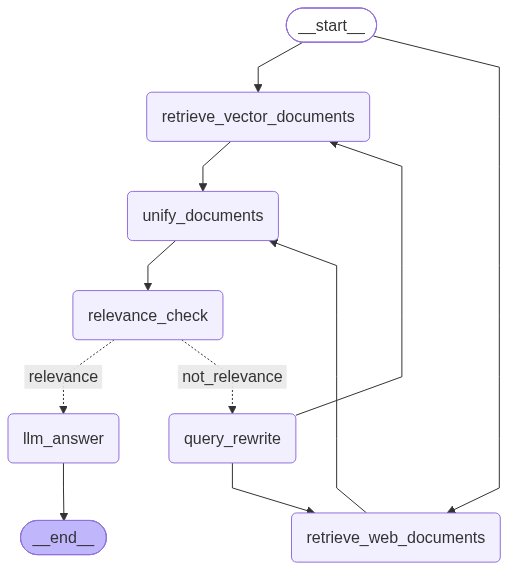

In [24]:
def showGraph(graph):
    # Show the graph
    from IPython.display import Image, display
    display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
    
graph = builder.compile()
showGraph(graph)